Citra RGB    : (490, 735, 3)
Citra Grayscale  : (490, 735)
Tinggi   : 490 Piksel
Lebar   : 735 Piksel
Jumlah   : 360150 Piksel
intensitas  0 :4
intensitas  1 :2
intensitas  2 :2
intensitas  3 :3
intensitas  4 :1
intensitas  5 :4
intensitas  6 :4
intensitas  7 :5
intensitas  8 :6
intensitas  9 :8
intensitas 10 :9
intensitas 11 :12
intensitas 12 :21
intensitas 13 :15
intensitas 14 :16
intensitas 15 :17
intensitas 16 :16
intensitas 17 :19
intensitas 18 :20
intensitas 19 :17
intensitas 20 :11
intensitas 21 :22
intensitas 22 :24
intensitas 23 :30
intensitas 24 :26
intensitas 25 :34
intensitas 26 :28
intensitas 27 :34
intensitas 28 :33
intensitas 29 :34
intensitas 30 :45
intensitas 31 :59
intensitas 32 :58
intensitas 33 :68
intensitas 34 :94
intensitas 35 :119
intensitas 36 :264
intensitas 37 :465
intensitas 38 :1121
intensitas 39 :1394
intensitas 40 :2032
intensitas 41 :2018
intensitas 42 :2297
intensitas 43 :2398
intensitas 44 :2088
intensitas 45 :1911
intensitas 46 :1933
intensitas 47 :19

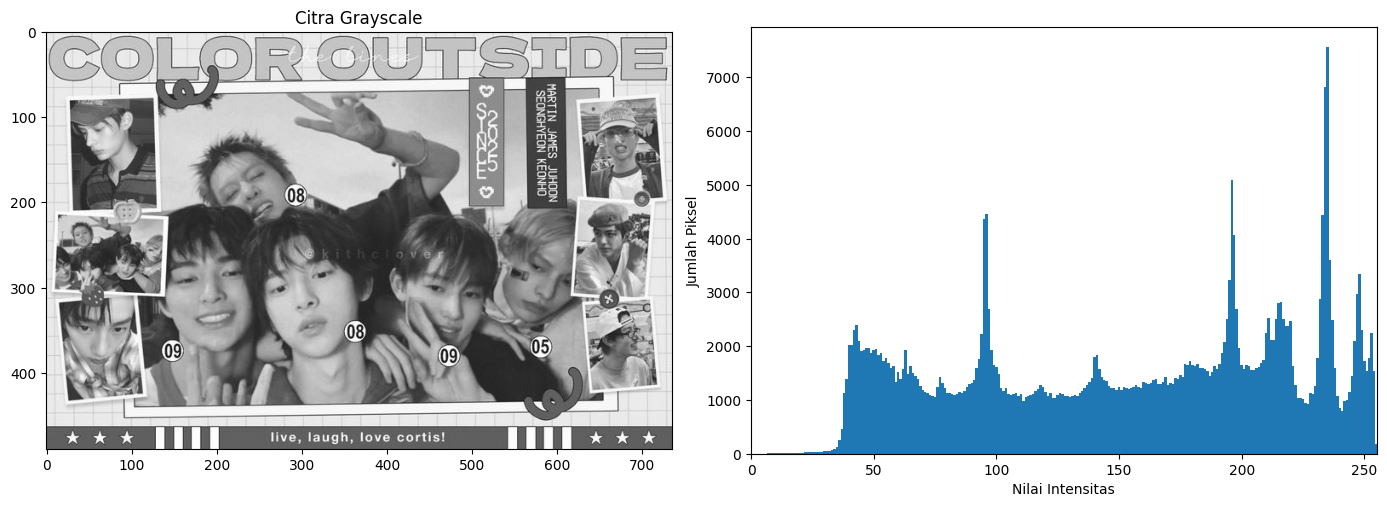

In [2]:
import imageio.v2 as imageio
import numpy as np
import matplotlib.pyplot as plt

nama_file = "ntiss.jpeg"

#1. membaca citra
img = imageio.imread(nama_file)
print("Citra RGB    :",img.shape)

#2. mengubah citra rgb ke gray
R = img[:,:,0]
G = img[:,:,1]
B = img[:,:,2]

img_gray = (
    0.299 * R +
    0.587 * G +
    0.114 * B
).astype(np.uint8)

print("Citra Grayscale  :",img_gray.shape)

#3. Hitung piksel
tinggi, lebar = img_gray.shape
jumlah_piksel = img_gray.size

print("Tinggi   :",tinggi, "Piksel")
print("Lebar   :",lebar, "Piksel")
print("Jumlah   :",jumlah_piksel, "Piksel")

#4. menghitung histogram
histogram = np.bincount(
    img_gray.flatten(),
    minlength=256
)

#5. menghitung intensitas
for intensitas in range(256):
    print(
        f"intensitas{intensitas: 3d} :"
        f"{histogram[intensitas]}"
    )

#6. mencari intensitas dominan
intensitas_dominan = np.argmax(histogram)
jumlah_intensitas = histogram[intensitas_dominan]

print("Intensitas Dominan   :",intensitas_dominan)
print("Jumlah Intensitas    :", jumlah_intensitas)

#7. tampilkan gambar
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.imshow(img_gray, cmap="gray")
plt.title("Citra Grayscale")


plt.subplot(1,2,2)
plt.bar(
    range(256),
    histogram,
    width=1
)

plt.ylabel("Jumlah Piksel")
plt.xlabel("Nilai Intensitas")
plt.xlim(0,255)

plt.tight_layout()
plt.show()